[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L2/BA_L2_metcalfe/BA_L2_metcalfe.ipynb)

# BA_L2_metcalfe: Market Value against Metcalfe Value

*Quantlet of Lecture 2, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Metcalfe's law for Bitcoin: log market value regressed on log transactions per day (monthly means, November 2014 to October 2025, Newey-West standard errors), and the ratio of market value to the Metcalfe value with the elasticity fixed at 2.

In [1]:
# packages that are not preinstalled on Colab
import importlib, subprocess, sys
for pkg in ['statsmodels']:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)

In [2]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [3]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [4]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [5]:
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10, 'lines.linewidth': 1.5})   # as in the slide charts
END = '2026-09-18'


def slide_legend(fig, bottom, ncol=3):
    # one legend for the whole figure, under the plots, as in the slides
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))


def prices(sym):
    # every positive daily close in the file, to 18 September 2026
    return daily(sym, END)


def rets(p, start='2018-01-01'):
    # daily log returns in percent, r_t = 100 (ln P_t - ln P_{t-1})
    return (100 * np.log(p).diff()).dropna().loc[start:]

## Data and method

**Metcalfe's law** says that the value of a network grows with the square of its users $n$. As a regression on logs,

$$\ln M_t = a + b \ln n_t + u_t, \qquad \text{Metcalfe: } b = 2,$$

where $M_t$ is Bitcoin's market value and $n_t$ transactions per day, a proxy for use (transactions are not users).
Data: monthly means, November 2014 to October 2025, with the 11 days of recording error (27 August to 6 September
2023) removed. Standard errors are Newey–West (heteroskedasticity- and autocorrelation-consistent) with 12 lags.

The **Metcalfe value** fixes $b = 2$: $\exp(\hat c + 2\ln n_t)$, with $\hat c$ the mean of $\ln M_t - 2\ln n_t$, so
that the ratio of market value to Metcalfe value is 1 on average in logs.

**How to read the chart.** Left: market value and Metcalfe value, log scale. Right: their ratio, log scale; above 2
the market value is high relative to activity, below 0.5 low. The ratio depends on the model ($b = 2$) and on the
proxy; it is a diagnostic, not a fair value.

In [6]:
import statsmodels.api as sm

tx_btc = pd.to_numeric(onchain('transaction')['BTC'], errors='coerce')
mc_btc = pd.to_numeric(onchain('Mktcap')['BTC'], errors='coerce')
mc_btc.loc['2023-08-27':'2023-09-06'] = np.nan                     # recording error (Lecture 1)
mm = pd.DataFrame({'tx': tx_btc, 'mc': mc_btc}).dropna().resample('ME').mean().dropna()
y, x = np.log(mm['mc']), np.log(mm['tx'])
print(f'Monthly means: {len(mm)} months, {mm.index[0]:%B %Y} to {mm.index[-1]:%B %Y}')

Monthly means: 132 months, November 2014 to October 2025


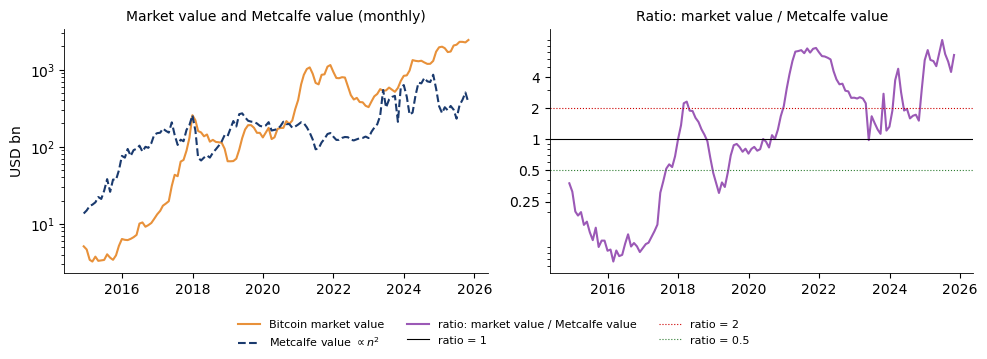

In [7]:
res = sm.OLS(y, sm.add_constant(x)).fit(cov_type='HAC', cov_kwds={'maxlags': 12})
c = (y - 2 * x).mean()
ratio = np.exp(y - (c + 2 * x))                     # market value / Metcalfe value

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(mm.index, mm['mc'] / 1e9, color=BTC, label='Bitcoin market value')
ax[0].plot(mm.index, np.exp(c + 2 * x) / 1e9, color=BLUE, ls='--', label=r'Metcalfe value $\propto n^2$')
ax[0].set_yscale('log'); ax[0].set_ylabel('USD bn')
ax[0].set_title('Market value and Metcalfe value (monthly)', fontsize=10)
ax[1].plot(ratio.index, ratio, color=ETH, label='ratio: market value / Metcalfe value')
ax[1].axhline(1, color='black', lw=0.8, label='ratio = 1')
ax[1].axhline(2, color=RED, lw=0.8, ls=':', label='ratio = 2'); ax[1].axhline(0.5, color=GREEN, lw=0.8, ls=':', label='ratio = 0.5')
ax[1].set_yscale('log'); ax[1].set_yticks([0.25, 0.5, 1, 2, 4]); ax[1].set_yticklabels(['0.25', '0.5', '1', '2', '4'])
ax[1].set_title('Ratio: market value / Metcalfe value', fontsize=10)
h, l = [], []
for a_ in ax:
    hh, ll = a_.get_legend_handles_labels(); h += hh; l += ll
fig.legend(h, l, loc='lower center', ncol=3, frameon=False, fontsize=8)
fig.tight_layout(rect=(0, 0.12, 1, 1))
save_fig(fig, 'ba_l2_metcalfe')

In [8]:
bhat, se = res.params.iloc[1], res.bse.iloc[1]
print(f'Elasticity b = {bhat:.2f} (Newey-West SE {se:.2f}); R2 = {res.rsquared:.2f}; t for b = 2: {(bhat - 2) / se:.2f}')
print(f'Ratio: maximum {ratio.max():.1f} ({ratio.idxmax():%B %Y}), minimum {ratio.min():.2f} ({ratio.idxmin():%B %Y}), '
      f'last {ratio.iloc[-1]:.2f} ({ratio.index[-1]:%B %Y})')
print(f'Share of months with ratio above 2: {100 * (ratio > 2).mean():.0f}%; below 0.5: {100 * (ratio < 0.5).mean():.0f}%')
print('Years with a monthly ratio above 4:', sorted(set(ratio[ratio > 4].index.year)))
print('Years with a monthly ratio below 0.5:', sorted(set(ratio[ratio < 0.5].index.year)))

Elasticity b = 3.59 (Newey-West SE 0.43); R2 = 0.58; t for b = 2: 3.66
Ratio: maximum 9.1 (June 2025), minimum 0.07 (February 2016), last 6.51 (October 2025)
Share of months with ratio above 2: 36%; below 0.5: 30%
Years with a monthly ratio above 4: [2021, 2022, 2024, 2025]
Years with a monthly ratio below 0.5: [2014, 2015, 2016, 2017, 2018, 2019]
